In [ ]:

%pip install -q scikit-learn pandas numpy matplotlib seaborn joblib


In [2]:

# Data Manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

# Model Saving
import joblib
from pathlib import Path




# Machine Learning Assignment 2
## Comparative Analysis of Classification Algorithms for Email Spam Detection

**Institution:** BITS Pilani  
**Course:** Machine Learning  
**BITS ID:** 2026AK05228  
**Assignment:** 2

---

### 1. Problem Statement

Email spam detection is a binary classification problem
where emails are categorized as spam or legitimate.

The objective of this assignment is to implement,
evaluate, and compare five supervised machine learning
algorithms using the UCI Spambase dataset.

### 2. Objectives

1. Perform exploratory data analysis and preprocessing.
2. Implement five classification algorithms:
   - Logistic Regression
   - Decision Tree
   - K-Nearest Neighbors (KNN)
   - Gaussian Naive Bayes
   - Support Vector Machine (SVM)
3. Evaluate all models using six metrics:
   Accuracy, ROC AUC, Precision, Recall, F1, and MCC.
4. Compare classification performance and analyze errors.
5. Identify the best-performing classifier.
6. Save trained models and deploy an interactive
   Streamlit application for testing predictions.

### 3. Experimental Approach

All classifiers will use the same cleaned dataset
and stratified 80:20 train-test split.

A fixed random state of 42 will be used to ensure
reproducibility.

Feature scaling will be applied through training
pipelines wherever appropriate to prevent data leakage.



## 2. Dataset Selection and Description

### Dataset: Spambase

**Source:** UCI Machine Learning Repository  
**Dataset URL:** https://archive.ics.uci.edu/dataset/94/spambase

### Dataset Characteristics

| Property | Description |
|---|---|
| Problem type | Binary Classification |
| Total observations | 4,601 |
| Input features | 57 |
| Target variable | spam |
| Class 0 | Non-Spam |
| Class 1 | Spam |
| Feature types | Numerical |

### Feature Description

The dataset contains numerical features representing
word frequencies, special-character frequencies, and
capital-letter sequence characteristics in emails.

### Why This Dataset?

The Spambase dataset was selected because it satisfies
the assignment requirements of at least 500 observations
and 12 input features.

It also provides a practical classification problem where
different algorithms can be evaluated under identical
experimental conditions.


In [6]:

# Load the UCI Spambase dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.data"

df = pd.read_csv(url, header=None)

# Assign column names
df.columns = [f"feature_{i:02d}" for i in range(1, 58)] + ["spam"]

# Display basic dataset information
print("Dataset dimensions:", df.shape)
print("Number of input features:", df.shape[1] - 1)
print("Target variable:", df.columns[-1])

# Preview the first five records
display(df.head())


Dataset dimensions: (4601, 58)
Number of input features: 57
Target variable: spam


,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,feature_08,feature_09,feature_10,...,feature_49,feature_50,feature_51,feature_52,feature_53,feature_54,feature_55,feature_56,feature_57,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1



## 3. Exploratory Data Analysis (EDA)

### Objective

To understand the dataset's structure, feature
characteristics, class distribution, and potential
data-quality issues before model development.

### Analysis Performed

1. Examined dataset dimensions and data types.
2. Checked for missing values and duplicate records.
3. Calculated descriptive statistics for the features.
4. Visualized the target-class distribution.

### Observations

The initial dataset contains 4,601 email records.

- Non-Spam emails: 2,788 (60.6%)
- Spam emails: 1,813 (39.4%)
- Missing values: 0
- Duplicate records: 391
- All input features are numerical.

### Interpretation

The dataset contains more legitimate emails than spam
emails, indicating a moderate class imbalance.

The absence of missing values simplifies preprocessing,
while duplicate records require further examination.

Feature standard deviations differ considerably,
suggesting that feature scaling may be important for
distance-based and optimization-based classifiers.

### Key Takeaway

A stratified train-test split will be used to maintain
the class proportions across training and testing sets.

Accuracy alone may not provide a complete evaluation,
so additional metrics will be used to assess performance.


Dataset Dimensions: (4601, 58)

Data Types:
float64    55
int64       3
Name: count, dtype: int64

Missing Values: 0
Duplicate Records: 391

Descriptive Statistics:


,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,feature_08,feature_09,feature_10,...,feature_49,feature_50,feature_51,feature_52,feature_53,feature_54,feature_55,feature_56,feature_57,spam
count,4601.000,4601.000,4601.000,4601.000,4601.000,4601.000,4601.000,4601.000,4601.000,4601.000,...,4601.000,4601.000,4601.000,4601.000,4601.000,4601.000,4601.000,4601.000,4601.000,4601.000
mean,0.105,0.213,0.281,0.065,0.312,0.096,0.114,0.105,0.090,0.239,...,0.039,0.139,0.017,0.269,0.076,0.044,5.192,52.173,283.289,0.394
std,0.305,1.291,0.504,1.395,0.673,0.274,0.391,0.401,0.279,0.645,...,0.243,0.270,0.109,0.816,0.246,0.429,31.729,194.891,606.348,0.489
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,1.000,0.000
25%,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,1.588,6.000,35.000,0.000
50%,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.065,0.000,0.000,0.000,0.000,2.276,15.000,95.000,0.000
75%,0.000,0.000,0.420,0.000,0.380,0.000,0.000,0.000,0.000,0.160,...,0.000,0.188,0.000,0.315,0.052,0.000,3.706,43.000,266.000,1.000
max,4.540,14.280,5.100,42.810,10.000,5.880,7.270,11.110,5.260,18.180,...,4.385,9.752,4.081,32.478,6.003,19.829,1102.500,9989.000,15841.000,1.000



Target Class Distribution:
spam
0    2788
1    1813
Name: count, dtype: int64

Class Distribution (%):
spam
0    60.6
1    39.4
Name: count, dtype: float64


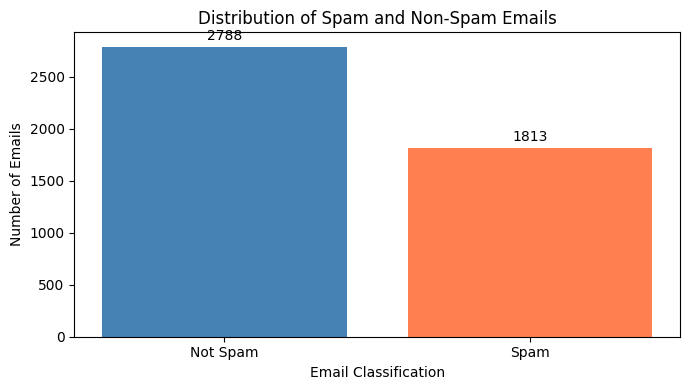

In [8]:

# ============================================================
# STEP 3: EXPLORATORY DATA ANALYSIS
# ============================================================

# 1. Dataset Structure
print("Dataset Dimensions:", df.shape)
print("\nData Types:")
print(df.dtypes.value_counts())

# 2. Data Quality
print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

# 3. Descriptive Statistics
print("\nDescriptive Statistics:")
display(df.describe().round(3))

# 4. Class Distribution
print("\nTarget Class Distribution:")
class_counts = df["spam"].value_counts().sort_index()
print(class_counts)

print("\nClass Distribution (%):")
print((class_counts / len(df) * 100).round(2))

# 5. Class Distribution Visualization
fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    ["Not Spam", "Spam"],
    class_counts.values,
    color=["steelblue", "coral"]
)

ax.bar_label(bars, padding=3)
ax.set_title("Distribution of Spam and Non-Spam Emails")
ax.set_xlabel("Email Classification")
ax.set_ylabel("Number of Emails")

plt.tight_layout()
plt.show()



### 3.5 EDA Observations and Interpretation

#### Dataset Quality Assessment

| Parameter | Observation |
|---|---|
| Total records | 4,601 |
| Input features | 57 |
| Missing values | 0 |
| Duplicate records | 391 |
| Non-Spam emails | 2,788 (60.60%) |
| Spam emails | 1,813 (39.40%) |

#### Key Findings

**1. Data Completeness**

No missing values were identified. Therefore,
missing-value imputation is not required.

**2. Duplicate Observations**

391 exact duplicate records were identified.
These will be removed before train-test splitting
to reduce the risk of identical records appearing
in both datasets.

**3. Class Distribution**

The dataset contains approximately 60.6% legitimate
emails and 39.4% spam emails.

This indicates moderate class imbalance. Stratified
sampling will be used to preserve class proportions
in the training and testing datasets.

**4. Feature Characteristics**

All input features are numerical. However, their
scales and distributions differ considerably.

Feature standardization will be applied to
Logistic Regression, KNN, and SVM through pipelines.

**5. Evaluation Implications**

Accuracy alone may not adequately capture the
trade-off between detecting spam and incorrectly
flagging legitimate emails.

Precision, Recall, F1, AUC, and MCC will provide
a more comprehensive assessment.

### 3.6 Conclusion

The dataset satisfies the assignment requirements.
Data cleaning is necessary before model training,
primarily to address duplicate observations.



## 4. Data Cleaning and Preparation

### Objective

To prepare a consistent dataset for training and
evaluating classification algorithms.

### Methodology

**Missing Values:** No missing values were identified,
so imputation is unnecessary.

**Duplicate Records:** 391 exact duplicate rows were
identified during EDA.

For this experiment, exact duplicates will be removed
before splitting the data. This reduces the possibility
of identical observations appearing in both training
and test datasets.

**Feature Types:** All features are numerical and do not
require categorical encoding.

### Considerations

Removing duplicate rows may also remove legitimate
repeated observations. This is a preprocessing choice,
and its effect should be considered when interpreting
the model results.

### Expected Outcome

After removing the 391 duplicate records, the dataset
should contain 4,210 unique rows and 58 columns,
including the target variable.


In [11]:

# ============================================================
# STEP 4: DATA CLEANING AND VALIDATION
# ============================================================

# Record original dataset size
original_rows = len(df)

# Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Validate cleaned dataset
print("Original Records:", original_rows)
print("Duplicate Records Removed:", original_rows - len(df))
print("Cleaned Dataset Shape:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())
print("Missing Values:", df.isnull().sum().sum())

# Verify data quality
assert df.duplicated().sum() == 0
assert df.isnull().sum().sum() == 0
assert df.shape[1] == 58

print("\nData cleaning completed successfully!")

# Preview cleaned data
display(df.head())


Original Records: 4601
Duplicate Records Removed: 391
Cleaned Dataset Shape: (4210, 58)
Remaining Duplicates: 0
Missing Values: 0

Data cleaning completed successfully!


,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,feature_08,feature_09,feature_10,...,feature_49,feature_50,feature_51,feature_52,feature_53,feature_54,feature_55,feature_56,feature_57,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1



## 5. Train-Test Split

### 5.1 Objective

To divide the cleaned dataset into independent
training and testing subsets for evaluating
the generalization performance of classifiers.

### 5.2 Methodology

An 80:20 stratified train-test split will be used.

| Parameter | Configuration |
|---|---|
| Training proportion | 80% |
| Testing proportion | 20% |
| Random state | 42 |
| Sampling strategy | Stratified |
| Input features | 57 |
| Target variable | spam |

### 5.3 Rationale

**Training Set (80%)**

Used to learn model parameters and classification
patterns from historical email observations.

**Testing Set (20%)**

Reserved for evaluating model performance on
previously unseen observations.

**Stratified Sampling**

Maintains approximately the same proportion of
spam and non-spam emails in both subsets.

**Reproducibility**

A fixed random state of 42 ensures that repeated
experiments produce the same train-test partition.

### 5.4 Data Leakage Prevention

The test dataset will not be used for model training
or fitting preprocessing transformations.

Feature scaling will be incorporated into
model-specific pipelines.

All five classification algorithms will use the
same training and testing observations to ensure
a consistent comparison.

### 5.5 Expected Outcome

The cleaned dataset contains 4,210 observations.

Expected partition:

- Training observations: 3,368
- Testing observations: 842

The resulting datasets will be used for subsequent
classification experiments.


In [14]:

# ============================================================
# STEP 5: STRATIFIED TRAIN-TEST SPLIT
# ============================================================

# Separate input features and target
X = df.drop(columns=["spam"])
y = df["spam"]

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training Dataset:", X_train.shape)
print("Testing Dataset:", X_test.shape)

# Verify class distribution
class_distribution = pd.DataFrame({
    "Full Dataset (%)": y.value_counts(normalize=True) * 100,
    "Training (%)": y_train.value_counts(normalize=True) * 100,
    "Testing (%)": y_test.value_counts(normalize=True) * 100
})

class_distribution.index = class_distribution.index.map({
    0: "Not Spam",
    1: "Spam"
})

print("\nClass Distribution:")
display(class_distribution.round(2))

# Validate split integrity
assert len(X_train) + len(X_test) == len(df)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert X_train.shape[1] == 57

print("\nTrain-test split validated successfully!")


Training Dataset: (3368, 57)
Testing Dataset: (842, 57)

Class Distribution:


,Full Dataset (%),Training (%),Testing (%)
spam,,,
Not Spam,60.12,60.12,60.1
Spam,39.88,39.88,39.9



Train-test split validated successfully!



## 6. Classification Model Implementation

### 6.1 Logistic Regression

#### Objective

To develop a binary classification model that predicts
whether an email is spam or legitimate using 57
numerical input features.

#### Algorithm Overview

Logistic Regression is a supervised classification
algorithm that estimates the probability of an
observation belonging to a particular class.

It uses the sigmoid function:

$$
P(y=1|X)=\frac{1}{1+e^{-z}}
$$

Where:

$$
z=b+\sum_{i=1}^{n}w_ix_i
$$

The predicted probability is converted into a class
label using a decision threshold of 0.5.

#### Implementation Methodology

1. Use the existing training and testing datasets.
2. Standardize numerical features using StandardScaler.
3. Train Logistic Regression on the training dataset.
4. Generate class predictions and probabilities.
5. Calculate six classification evaluation metrics.
6. Visualize and interpret the confusion matrix.

#### Hyperparameter Configuration

| Parameter | Value |
|---|---|
| Regularization | L2 |
| C | 1.0 |
| Maximum iterations | 2000 |
| Random state | 42 |
| Decision threshold | 0.5 |

#### Data Leakage Prevention

A scikit-learn Pipeline will combine StandardScaler
and Logistic Regression.

The scaler will learn its parameters exclusively from
the training data. The fitted transformation will then
be applied to the test data.

#### Expected Outcome

A trained Logistic Regression classifier that provides
baseline performance for comparison with the other
four classification algorithms.


In [17]:

# ============================================================
# MODEL 1: LOGISTIC REGRESSION
# ============================================================

# Create preprocessing and classification pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l2",
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

# Train the model using training data only
logistic_model.fit(X_train, y_train)

# Predict class labels on unseen test data
lr_predictions = logistic_model.predict(X_test)

# Predict probabilities for the positive class (Spam = 1)
lr_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Verify predictions
print("Logistic Regression training completed!")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Predictions generated:", len(lr_predictions))

# Preview actual vs predicted labels
lr_preview = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": lr_predictions,
    "Spam Probability": lr_probabilities
})

display(lr_preview.head(10).round(4))


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Logistic Regression training completed!
Training observations: 3368
Testing observations: 842
Predictions generated: 842


,Actual,Predicted,Spam Probability
0,1,1,0.7939
1,0,0,0.0048
2,1,1,0.9976
3,1,0,0.4306
4,0,1,0.5982
5,0,0,0.0000
6,1,0,0.4553
7,1,1,0.9139
8,0,0,0.0000
9,1,1,0.8417



# ============================================================
# MODEL 1: LOGISTIC REGRESSION EVALUATION
# ============================================================

# Calculate six evaluation metrics
lr_metrics = {
    "Accuracy": accuracy_score(y_test, lr_predictions),
    "AUC": roc_auc_score(y_test, lr_probabilities),
    "Precision": precision_score(y_test, lr_predictions),
    "Recall": recall_score(y_test, lr_predictions),
    "F1": f1_score(y_test, lr_predictions),
    "MCC": matthews_corrcoef(y_test, lr_predictions)
}

# Initialize results dictionary for all five models
model_results = {}

# Store Logistic Regression results
model_results["Logistic Regression"] = lr_metrics

# Display evaluation results
lr_results_df = pd.DataFrame(
    [lr_metrics],
    index=["Logistic Regression"]
)

print("Logistic Regression - Evaluation Results")
display(lr_results_df.round(4))

# Display classification report
print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Not Spam", "Spam"]
))


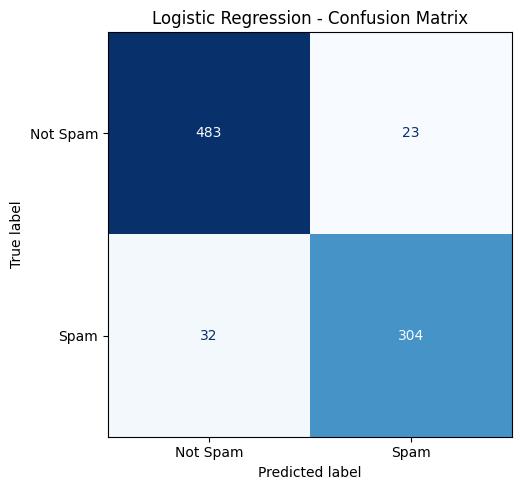

Confusion Matrix:
[[483  23]
 [ 32 304]]

Classification Breakdown:
True Negatives (TN): 483
False Positives (FP): 23
False Negatives (FN): 32
True Positives (TP): 304
Correct Predictions: 787
Incorrect Predictions: 55


In [20]:

# ============================================================
# MODEL 1: LOGISTIC REGRESSION CONFUSION MATRIX
# ============================================================

# Calculate confusion matrix
lr_cm = confusion_matrix(y_test, lr_predictions)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=["Not Spam", "Spam"]
)

disp.plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

# Extract confusion matrix components
tn, fp, fn, tp = lr_cm.ravel()

print("Confusion Matrix:")
print(lr_cm)

print("\nClassification Breakdown:")
print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)
print("Correct Predictions:", tn + tp)
print("Incorrect Predictions:", fp + fn)



### 6.1.1 Logistic Regression - Results and Interpretation

#### Evaluation Results

| Metric | Score |
|---|---:|
| Accuracy | 0.9347 |
| AUC | 0.9768 |
| Precision | 0.9297 |
| Recall | 0.9048 |
| F1-Score | 0.9170 |
| MCC | 0.8634 |

#### Confusion Matrix Analysis

| Actual / Predicted | Not Spam | Spam |
|---|---:|---:|
| Not Spam | 483 | 23 |
| Spam | 32 | 304 |

#### Key Observations

1. **Accuracy (93.47%):** The model correctly
   classified 787 out of 842 test emails.

2. **AUC (0.9768):** The model demonstrates excellent
   discrimination between spam and legitimate emails.

3. **Precision (92.97%):** Most emails predicted
   as spam were correctly classified.

4. **Recall (90.48%):** The model successfully
   detected 304 of 336 spam emails.

5. **F1-Score (0.9170):** The model maintains a
   strong balance between precision and recall.

6. **MCC (0.8634):** The model demonstrates strong
   overall classification performance.

#### Error Analysis

The model generated:
- 23 False Positives: Legitimate emails flagged as spam.
- 32 False Negatives: Spam emails classified as legitimate.

False positives are particularly important because
legitimate messages may be incorrectly filtered.

#### Interpretation

Logistic Regression demonstrates strong performance
on the Spambase dataset.

Its high AUC, F1-score, and MCC suggest that a
regularized linear classifier can effectively
distinguish spam from legitimate emails.

#### Conclusion

Logistic Regression provides a strong baseline for
the experiment.

Its performance will be compared with Decision Tree,
KNN, Gaussian Naive Bayes, and SVM before selecting
the overall best classifier.



### 6.2 Decision Tree Classifier

#### Objective

To implement a tree-based classification algorithm
that predicts whether an email is spam or legitimate
using decision rules learned from the input features.

#### Algorithm Overview

A Decision Tree is a supervised learning algorithm
that recursively partitions data into subsets based
on feature values.

Each internal node represents a decision condition,
each branch represents an outcome, and each leaf
node represents a predicted class.

For this experiment, Gini impurity is used to
evaluate candidate splits.

$$
Gini = 1 - \sum_{i=1}^{K} p_i^2
$$

Where:
- K represents the number of classes.
- p_i represents the proportion of class i.

Lower Gini impurity indicates a purer node.

#### Implementation Methodology

1. Use the same training and testing datasets.
2. Initialize a Decision Tree with Gini impurity.
3. Limit tree depth to control model complexity.
4. Train the classifier using training observations.
5. Generate predictions and class probabilities.
6. Calculate all six evaluation metrics.
7. Analyze the confusion matrix.
8. Compare performance against Logistic Regression.

#### Hyperparameter Configuration

| Parameter | Value |
|---|---|
| Criterion | Gini |
| Maximum depth | 6 |
| Minimum samples per leaf | 5 |
| Random state | 42 |
| Feature scaling | Not required |

#### Model Considerations

Decision Trees can capture nonlinear relationships
and interactions between input features.

However, unrestricted trees may overfit training
data and generalize poorly to unseen observations.

Maximum depth and minimum leaf size are used
to control model complexity.

#### Expected Outcome

A trained Decision Tree classifier evaluated on
the same 842 test observations used for
Logistic Regression.


In [34]:

# ============================================================
# MODEL 2: DECISION TREE CLASSIFIER
# ============================================================

# 1. Initialize shared results dictionary
if "model_results" not in globals():
    model_results = {}

# 2. Recover Logistic Regression metrics if available
if "lr_predictions" in globals() and "lr_probabilities" in globals():
    lr_metrics = {
        "Accuracy": accuracy_score(y_test, lr_predictions),
        "AUC": roc_auc_score(y_test, lr_probabilities),
        "Precision": precision_score(y_test, lr_predictions),
        "Recall": recall_score(y_test, lr_predictions),
        "F1": f1_score(y_test, lr_predictions),
        "MCC": matthews_corrcoef(y_test, lr_predictions)
    }

    model_results["Logistic Regression"] = lr_metrics
    print("Logistic Regression results recovered.")
else:
    print("Note: Run Cell 13 to recover Logistic Regression predictions.")

# 3. Initialize Decision Tree
decision_tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=6,
    min_samples_leaf=5,
    random_state=42
)

# 4. Train model
decision_tree_model.fit(X_train, y_train)

# 5. Generate predictions
dt_predictions = decision_tree_model.predict(X_test)
dt_probabilities = decision_tree_model.predict_proba(X_test)[:, 1]

# 6. Display training information
print("\nDecision Tree training completed!")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Predictions generated:", len(dt_predictions))
print("Actual tree depth:", decision_tree_model.get_depth())
print("Number of leaf nodes:", decision_tree_model.get_n_leaves())

# 7. Preview predictions
dt_preview = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": dt_predictions,
    "Spam Probability": dt_probabilities
})

display(dt_preview.head(10).round(4))


Logistic Regression results recovered.

Decision Tree training completed!
Training observations: 3368
Testing observations: 842
Predictions generated: 842
Actual tree depth: 6
Number of leaf nodes: 31


,Actual,Predicted,Spam Probability
0,1,0,0.3846
1,0,0,0.0573
2,1,1,0.9803
3,1,0,0.0769
4,0,1,0.9815
5,0,0,0.0573
6,1,0,0.0573
7,1,1,0.9803
8,0,0,0.0573
9,1,1,0.9803


In [38]:

# ============================================================
# MODEL 2: DECISION TREE EVALUATION
# CELL 19 - UPDATED
# ============================================================

# Initialize results dictionary if needed
if "model_results" not in globals():
    model_results = {}

# Calculate Decision Tree metrics
dt_metrics = {
    "Accuracy": accuracy_score(y_test, dt_predictions),
    "AUC": roc_auc_score(y_test, dt_probabilities),
    "Precision": precision_score(y_test, dt_predictions),
    "Recall": recall_score(y_test, dt_predictions),
    "F1": f1_score(y_test, dt_predictions),
    "MCC": matthews_corrcoef(y_test, dt_predictions)
}

# Store results
model_results["Decision Tree"] = dt_metrics

# Display model comparison
comparison_df = pd.DataFrame.from_dict(
    model_results,
    orient="index"
)

print("Classification Model Comparison:")
display(comparison_df.round(4))

# Detailed classification report
print("\nDecision Tree Classification Report:")
print(classification_report(
    y_test,
    dt_predictions,
    target_names=["Not Spam", "Spam"]
))


Classification Model Comparison:


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9347,0.9768,0.9297,0.9048,0.9170,0.8634
Decision Tree,0.8848,0.9259,0.8567,0.8542,0.8554,0.7597



Decision Tree Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.90      0.91      0.90       506
        Spam       0.86      0.85      0.86       336

    accuracy                           0.88       842
   macro avg       0.88      0.88      0.88       842
weighted avg       0.88      0.88      0.88       842



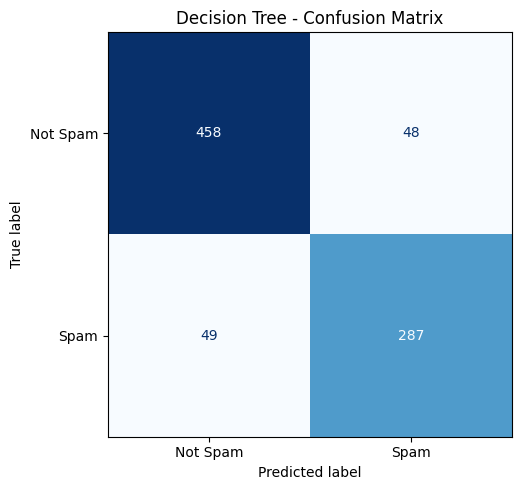

Confusion Matrix:
[[458  48]
 [ 49 287]]

Classification Breakdown:
True Negatives (TN): 458
False Positives (FP): 48
False Negatives (FN): 49
True Positives (TP): 287
Correct Predictions: 745
Incorrect Predictions: 97


In [36]:

# ============================================================
# MODEL 2: DECISION TREE CONFUSION MATRIX
# ============================================================

# Calculate confusion matrix
dt_cm = confusion_matrix(y_test, dt_predictions)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=dt_cm,
    display_labels=["Not Spam", "Spam"]
)

disp.plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

# Extract confusion matrix components
tn, fp, fn, tp = dt_cm.ravel()

print("Confusion Matrix:")
print(dt_cm)

print("\nClassification Breakdown:")
print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)
print("Correct Predictions:", tn + tp)
print("Incorrect Predictions:", fp + fn)



### 6.2.1 Decision Tree - Results and Interpretation

#### Evaluation Results

| Metric | Decision Tree | Logistic Regression |
|---|---:|---:|
| Accuracy | 0.8848 | 0.9347 |
| AUC | 0.9259 | 0.9768 |
| Precision | 0.8567 | 0.9297 |
| Recall | 0.8542 | 0.9048 |
| F1-Score | 0.8554 | 0.9170 |
| MCC | 0.7597 | 0.8634 |

#### Confusion Matrix Analysis

| Actual / Predicted | Not Spam | Spam |
|---|---:|---:|
| Not Spam | 458 | 48 |
| Spam | 49 | 287 |

#### Key Observations

1. **Accuracy (88.48%):** The Decision Tree correctly
   classified 745 out of 842 test emails.

2. **AUC (0.9259):** The model demonstrates good
   discrimination between spam and legitimate emails.

3. **Precision (85.67%):** Approximately 86% of emails
   predicted as spam were correctly classified.

4. **Recall (85.42%):** The model detected 287 of
   336 actual spam emails.

5. **F1-Score (0.8554):** Precision and recall are
   reasonably balanced.

6. **MCC (0.7597):** The model demonstrates positive
   classification performance across both classes.

#### Error Analysis

The model produced:
- 48 false positives: Legitimate emails flagged as spam.
- 49 false negatives: Spam emails classified as legitimate.

Compared with Logistic Regression, the Decision Tree
produced more classification errors.

#### Interpretation

Decision Trees can model nonlinear relationships
and feature interactions without requiring scaling.

However, the selected tree configuration achieved
lower accuracy, F1-score, and MCC than Logistic
Regression on the same test dataset.

Limiting tree depth helps control model complexity,
but may also restrict the patterns the model learns.

#### Conclusion

Logistic Regression currently outperforms Decision
Tree across all six evaluation metrics.

The Decision Tree remains useful as an interpretable
classification approach, but its predictive performance
was weaker in this experiment.



### 6.3 K-Nearest Neighbors (KNN) Classifier

#### Objective

To implement an instance-based classification algorithm
that predicts whether an email is spam or legitimate
based on its similarity to training observations.

#### Algorithm Overview

K-Nearest Neighbors (KNN) is a supervised,
non-parametric, instance-based learning algorithm.

Unlike Logistic Regression and Decision Trees,
KNN does not explicitly learn a decision function
during training. Instead, it stores training observations
and performs classification using nearby examples.

For a new observation, KNN:

1. Calculates distances to training observations.
2. Identifies the K nearest neighbors.
3. Determines the majority class among those neighbors.
4. Assigns the majority class to the new observation.

#### Distance Metric

Euclidean distance is used to measure similarity:

$$
d(x,y)=\sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}
$$

Where:
- x and y represent feature vectors.
- n represents the number of input features.
- d represents the distance between observations.

#### Implementation Methodology

1. Use the same training and testing datasets.
2. Standardize numerical features using StandardScaler.
3. Initialize KNN with K = 7.
4. Train the classifier using training observations.
5. Generate class predictions and probabilities.
6. Calculate all six evaluation metrics.
7. Analyze the confusion matrix.
8. Compare performance with previous classifiers.

#### Hyperparameter Configuration

| Parameter | Value |
|---|---|
| Number of neighbors (K) | 7 |
| Distance metric | Euclidean |
| Neighbor weighting | Uniform |
| Feature scaling | StandardScaler |

#### Model Considerations

**Importance of Scaling**

KNN is sensitive to differences in feature magnitude.
Features with larger numerical ranges may dominate
distance calculations.

StandardScaler will be applied using a Pipeline to
prevent data leakage.

**Bias-Variance Trade-off**

A smaller K may produce a more flexible classifier
but increase sensitivity to noise.

A larger K generally produces smoother decision
boundaries but may overlook local patterns.

K = 7 is selected as an initial experimental
configuration rather than an optimized value.

#### Expected Outcome

A trained KNN classifier evaluated on the same
842 test observations used for Logistic Regression
and Decision Tree.


In [42]:

# ============================================================
# MODEL 3: K-NEAREST NEIGHBORS (KNN)
# ============================================================

# Initialize KNN with feature scaling
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=7,
        weights="uniform",
        metric="euclidean"
    ))
])

# Train using training data only
knn_model.fit(X_train, y_train)

# Predict class labels on unseen test data
knn_predictions = knn_model.predict(X_test)

# Predict probabilities for Spam = 1
knn_probabilities = knn_model.predict_proba(X_test)[:, 1]

# Verify predictions
print("KNN training completed!")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Predictions generated:", len(knn_predictions))
print("Number of neighbors:", 7)

# Preview actual vs predicted results
knn_preview = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": knn_predictions,
    "Spam Probability": knn_probabilities
})

display(knn_preview.head(10).round(4))


KNN training completed!
Training observations: 3368
Testing observations: 842
Predictions generated: 842
Number of neighbors: 7


,Actual,Predicted,Spam Probability
0,1,1,0.5714
1,0,0,0.0000
2,1,1,1.0000
3,1,0,0.2857
4,0,0,0.1429
5,0,0,0.0000
6,1,0,0.2857
7,1,1,1.0000
8,0,0,0.0000
9,1,1,0.7143


In [44]:

# ============================================================
# MODEL 3: KNN EVALUATION
# ============================================================

# Calculate six evaluation metrics
knn_metrics = {
    "Accuracy": accuracy_score(y_test, knn_predictions),
    "AUC": roc_auc_score(y_test, knn_probabilities),
    "Precision": precision_score(y_test, knn_predictions),
    "Recall": recall_score(y_test, knn_predictions),
    "F1": f1_score(y_test, knn_predictions),
    "MCC": matthews_corrcoef(y_test, knn_predictions)
}

# Preserve previous results and add KNN
if "model_results" not in globals():
    model_results = {}

model_results["KNN"] = knn_metrics

# Generate comparison table
comparison_df = pd.DataFrame.from_dict(
    model_results,
    orient="index"
)

print("Classification Model Comparison:")
display(comparison_df.round(4))

# Detailed classification report
print("\nKNN Classification Report:")
print(classification_report(
    y_test,
    knn_predictions,
    target_names=["Not Spam", "Spam"]
))


Classification Model Comparison:


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9347,0.9768,0.9297,0.9048,0.9170,0.8634
Decision Tree,0.8848,0.9259,0.8567,0.8542,0.8554,0.7597
KNN,0.9050,0.9570,0.9103,0.8452,0.8765,0.8009



KNN Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.90      0.94      0.92       506
        Spam       0.91      0.85      0.88       336

    accuracy                           0.90       842
   macro avg       0.91      0.89      0.90       842
weighted avg       0.91      0.90      0.90       842



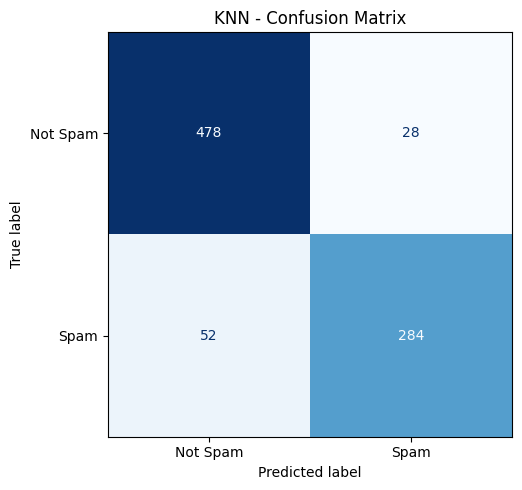

Confusion Matrix:
[[478  28]
 [ 52 284]]

Classification Breakdown:
True Negatives (TN): 478
False Positives (FP): 28
False Negatives (FN): 52
True Positives (TP): 284
Correct Predictions: 762
Incorrect Predictions: 80


In [46]:

# ============================================================
# MODEL 3: KNN CONFUSION MATRIX
# ============================================================

# Calculate confusion matrix
knn_cm = confusion_matrix(y_test, knn_predictions)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=knn_cm,
    display_labels=["Not Spam", "Spam"]
)

disp.plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("KNN - Confusion Matrix")
plt.tight_layout()
plt.show()

# Extract confusion matrix values
tn, fp, fn, tp = knn_cm.ravel()

print("Confusion Matrix:")
print(knn_cm)

print("\nClassification Breakdown:")
print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)
print("Correct Predictions:", tn + tp)
print("Incorrect Predictions:", fp + fn)



### 6.3.1 KNN - Results and Interpretation

#### Evaluation Results

| Metric | KNN | Logistic Regression | Decision Tree |
|---|---:|---:|---:|
| Accuracy | 0.9050 | 0.9347 | 0.8848 |
| AUC | 0.9570 | 0.9768 | 0.9259 |
| Precision | 0.9103 | 0.9297 | 0.8567 |
| Recall | 0.8452 | 0.9048 | 0.8542 |
| F1-Score | 0.8765 | 0.9170 | 0.8554 |
| MCC | 0.8009 | 0.8634 | 0.7597 |

#### Confusion Matrix Analysis

| Actual / Predicted | Not Spam | Spam |
|---|---:|---:|
| Not Spam | 478 | 28 |
| Spam | 52 | 284 |

#### Key Observations

1. **Accuracy (90.50%):** KNN correctly classified
   762 of 842 test emails.

2. **AUC (0.9570):** The model demonstrates strong
   discrimination between spam and legitimate emails.

3. **Precision (91.03%):** Most emails classified
   as spam were correctly identified.

4. **Recall (84.52%):** The model detected 284 of
   336 spam emails but missed 52.

5. **F1-Score (0.8765):** The model maintains a
   reasonable balance between precision and recall.

6. **MCC (0.8009):** The model demonstrates strong
   overall classification performance.

#### Error Analysis

KNN produced:
- 28 false positives: Legitimate emails flagged as spam.
- 52 false negatives: Spam emails classified as legitimate.

KNN missed more spam emails than Logistic Regression
and Decision Tree in this experiment.

#### Interpretation

KNN performed better than Decision Tree in accuracy,
precision, F1-score, AUC, and MCC.

However, Decision Tree achieved slightly higher recall.

Logistic Regression outperformed KNN across all
six evaluation metrics.

KNN's performance depends on the choice of K,
distance metric, and feature scaling.

The selected K=7 was not optimized using
cross-validation.

#### Conclusion

KNN achieved the second-highest F1-score and MCC
among the three classifiers evaluated so far.

Logistic Regression remains the leading model
based on overall predictive performance.



### 6.4 Gaussian Naive Bayes Classifier

#### Objective

To implement a probabilistic classification algorithm
that predicts whether an email is spam or legitimate
using Bayes' theorem.

#### Algorithm Overview

Naive Bayes is a supervised learning algorithm based
on conditional probability.

It applies Bayes' theorem:

$$
P(C|X)=\frac{P(X|C)P(C)}{P(X)}
$$

Where:

- P(C|X): Posterior probability of class C
- P(X|C): Likelihood of features given class C
- P(C): Prior probability of class C
- P(X): Evidence

The algorithm assumes that input features are
conditionally independent given the class label.

#### Gaussian Naive Bayes

Gaussian Naive Bayes assumes that each numerical
feature follows a Gaussian distribution within
each class.

The Gaussian probability density function is:

$$
P(x_i|C)=
\frac{1}{\sqrt{2\pi\sigma_C^2}}
\exp\left(
-\frac{(x_i-\mu_C)^2}{2\sigma_C^2}
\right)
$$

Where:
- x_i: Observed feature value
- mu_C: Feature mean for class C
- sigma_C²: Feature variance for class C

#### Implementation Methodology

1. Use the same training and testing datasets.
2. Initialize the Gaussian Naive Bayes classifier.
3. Train using the training observations.
4. Generate class predictions and probabilities.
5. Calculate all six evaluation metrics.
6. Analyze the confusion matrix.
7. Compare results with previous classifiers.

#### Hyperparameter Configuration

| Parameter | Value |
|---|---|
| Algorithm | Gaussian Naive Bayes |
| var_smoothing | 1e-9 |
| Feature scaling | Not required |
| Training observations | 3,368 |
| Testing observations | 842 |

#### Model Considerations

**Advantages**

- Computationally efficient.
- Simple probabilistic interpretation.
- Suitable for numerical classification features.

**Limitations**

The Spambase dataset contains word-frequency and
character-frequency features that may be skewed
rather than normally distributed.

Additionally, some email features may be correlated,
violating the conditional independence assumption.

These assumptions can influence classification
performance, particularly precision and recall.

#### Expected Outcome

A trained Gaussian Naive Bayes classifier evaluated
using the same test dataset as the previous models.

Its performance will help determine whether a
probabilistic classifier is competitive for
email spam detection.


In [50]:

# ============================================================
# MODEL 4: GAUSSIAN NAIVE BAYES CLASSIFIER
# ============================================================

# Initialize Gaussian Naive Bayes classifier
nb_model = GaussianNB(var_smoothing=1e-9)

# Train using training data only
nb_model.fit(X_train, y_train)

# Predict class labels on unseen test data
nb_predictions = nb_model.predict(X_test)

# Predict probabilities for Spam = 1
nb_probabilities = nb_model.predict_proba(X_test)[:, 1]

# Verify predictions
print("Gaussian Naive Bayes training completed!")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Predictions generated:", len(nb_predictions))
print("Variance smoothing:", nb_model.var_smoothing)

# Preview actual vs predicted results
nb_preview = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": nb_predictions,
    "Spam Probability": nb_probabilities
})

display(nb_preview.head(10).round(4))


Gaussian Naive Bayes training completed!
Training observations: 3368
Testing observations: 842
Predictions generated: 842
Variance smoothing: 1e-09


,Actual,Predicted,Spam Probability
0,1,1,1.0
1,0,0,0.0
2,1,1,1.0
3,1,1,1.0
4,0,1,1.0
5,0,0,0.0
6,1,1,1.0
7,1,1,1.0
8,0,0,0.0
9,1,1,1.0


In [52]:

# ============================================================
# MODEL 4: GAUSSIAN NAIVE BAYES EVALUATION
# ============================================================

# Calculate six evaluation metrics
nb_metrics = {
    "Accuracy": accuracy_score(y_test, nb_predictions),
    "AUC": roc_auc_score(y_test, nb_probabilities),
    "Precision": precision_score(y_test, nb_predictions),
    "Recall": recall_score(y_test, nb_predictions),
    "F1": f1_score(y_test, nb_predictions),
    "MCC": matthews_corrcoef(y_test, nb_predictions)
}

# Initialize results dictionary if necessary
if "model_results" not in globals():
    model_results = {}

# Store Naive Bayes results
model_results["Naive Bayes"] = nb_metrics

# Generate comparison table
comparison_df = pd.DataFrame.from_dict(
    model_results,
    orient="index"
)

print("Classification Model Comparison:")
display(comparison_df.round(4))

# Detailed classification report
print("\nGaussian Naive Bayes Classification Report:")
print(classification_report(
    y_test,
    nb_predictions,
    target_names=["Not Spam", "Spam"]
))


Classification Model Comparison:


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9347,0.9768,0.9297,0.9048,0.9170,0.8634
Decision Tree,0.8848,0.9259,0.8567,0.8542,0.8554,0.7597
KNN,0.9050,0.9570,0.9103,0.8452,0.8765,0.8009
Naive Bayes,0.8361,0.9525,0.7240,0.9524,0.8226,0.6975



Gaussian Naive Bayes Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.96      0.76      0.85       506
        Spam       0.72      0.95      0.82       336

    accuracy                           0.84       842
   macro avg       0.84      0.86      0.84       842
weighted avg       0.87      0.84      0.84       842



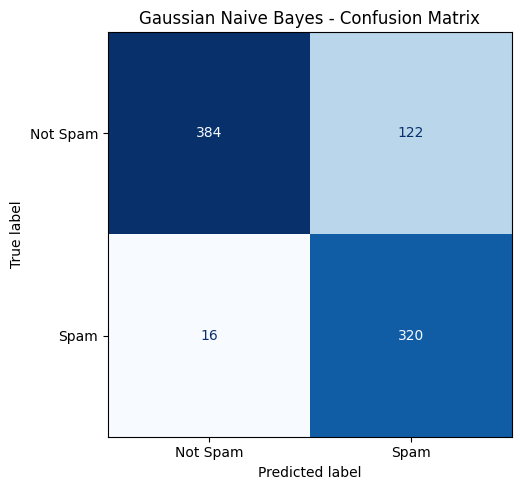

Confusion Matrix:
[[384 122]
 [ 16 320]]

Classification Breakdown:
True Negatives (TN): 384
False Positives (FP): 122
False Negatives (FN): 16
True Positives (TP): 320
Correct Predictions: 704
Incorrect Predictions: 138


In [54]:

# ============================================================
# MODEL 4: GAUSSIAN NAIVE BAYES CONFUSION MATRIX
# ============================================================

# Calculate confusion matrix
nb_cm = confusion_matrix(y_test, nb_predictions)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=nb_cm,
    display_labels=["Not Spam", "Spam"]
)

disp.plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.tight_layout()
plt.show()

# Extract confusion matrix values
tn, fp, fn, tp = nb_cm.ravel()

print("Confusion Matrix:")
print(nb_cm)

print("\nClassification Breakdown:")
print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)
print("Correct Predictions:", tn + tp)
print("Incorrect Predictions:", fp + fn)



### 6.4.1 Gaussian Naive Bayes - Results and Interpretation

#### Evaluation Results

| Metric | Score |
|---|---:|
| Accuracy | 0.8361 |
| AUC | 0.9525 |
| Precision | 0.7240 |
| Recall | 0.9524 |
| F1-Score | 0.8226 |
| MCC | 0.6975 |

#### Confusion Matrix Analysis

| Actual / Predicted | Not Spam | Spam |
|---|---:|---:|
| Not Spam | 384 | 122 |
| Spam | 16 | 320 |

#### Key Observations

1. **Accuracy (83.61%):** The model correctly classified
   704 out of 842 test emails.

2. **AUC (0.9525):** The model demonstrates strong
   discrimination between spam and legitimate emails.

3. **Precision (72.40%):** Approximately 72% of emails
   predicted as spam were actually spam.

4. **Recall (95.24%):** The model successfully identified
   320 out of 336 spam emails, achieving the highest
   recall among the four models evaluated so far.

5. **F1-Score (0.8226):** The lower F1-score reflects
   the imbalance between high recall and lower precision.

6. **MCC (0.6975):** The model shows positive predictive
   performance but ranks below the previous classifiers.

#### Error Analysis

The model produced:
- 122 false positives: Legitimate emails flagged as spam.
- 16 false negatives: Spam emails classified as legitimate.

Gaussian Naive Bayes detected more spam emails than
the other three models but incorrectly flagged
substantially more legitimate emails.

#### Interpretation

The model demonstrates a clear precision-recall trade-off.

Its high recall makes it effective at identifying spam,
but its lower precision is a concern for email filtering,
where incorrectly blocking legitimate messages may
have significant consequences.

The conditional independence and Gaussian distribution
assumptions may contribute to this behavior, although
the results alone do not establish the exact cause.

#### Conclusion

Gaussian Naive Bayes achieved the highest recall among
the four classifiers evaluated so far.

However, Logistic Regression remains the strongest
overall model based on accuracy, F1-score, and MCC.

The final SVM experiment will complete the five-model
comparison.



### 6.5 Support Vector Machine (SVM) Classifier

#### Objective

To implement a Support Vector Machine classifier
that distinguishes spam from legitimate emails
using a maximum-margin decision boundary.

#### Algorithm Overview

Support Vector Machine (SVM) is a supervised learning
algorithm used for classification and regression.

SVM identifies a decision boundary (hyperplane)
that separates observations belonging to different
classes while maximizing the margin between them.

The training observations closest to the decision
boundary are called **support vectors**.

For a linear SVM, the decision boundary is:

$$
w^Tx+b=0
$$

Where:
- w represents the weight vector.
- x represents the input feature vector.
- b represents the bias term.

#### RBF Kernel

This experiment uses the Radial Basis Function (RBF)
kernel to capture nonlinear relationships.

$$
K(x_i,x_j)=\exp(-\gamma\|x_i-x_j\|^2)
$$

The RBF kernel enables nonlinear classification
without explicitly constructing higher-dimensional
feature representations.

#### Implementation Methodology

1. Use the same training and testing datasets.
2. Standardize numerical features using StandardScaler.
3. Initialize SVM with the RBF kernel.
4. Train the model using training observations.
5. Generate class predictions and probabilities.
6. Calculate all six evaluation metrics.
7. Analyze the confusion matrix.
8. Compare SVM against the previous four classifiers.

#### Hyperparameter Configuration

| Parameter | Value |
|---|---|
| Kernel | RBF |
| C | 1.0 |
| Gamma | scale |
| Probability | True |
| Random state | 42 |
| Feature scaling | StandardScaler |

#### Model Considerations

**Advantages**

- Can capture nonlinear classification boundaries.
- Uses margin maximization to support generalization.
- Effective in high-dimensional feature spaces.

**Limitations**

- Training can become computationally expensive
  for large datasets.
- Performance depends on kernel and hyperparameters.
- Feature scaling is important.
- Probability estimation adds computational overhead.

#### Data Leakage Prevention

A scikit-learn Pipeline combines StandardScaler
and SVM.

The scaler is fitted exclusively on training data,
and the learned transformation is applied to
test observations.

#### Expected Outcome

A trained SVM classifier evaluated on the same
842 test observations used for the other models.

This experiment completes the implementation of
all five required classification algorithms.


In [58]:

# ============================================================
# MODEL 5: SUPPORT VECTOR MACHINE (SVM)
# ============================================================

# Initialize SVM with feature scaling
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

# Train using training data only
svm_model.fit(X_train, y_train)

# Predict class labels on unseen test data
svm_predictions = svm_model.predict(X_test)

# Predict probabilities for Spam = 1
svm_probabilities = svm_model.predict_proba(X_test)[:, 1]

# Verify predictions
print("SVM training completed!")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Predictions generated:", len(svm_predictions))
print("Kernel: RBF")

# Display number of support vectors
print("Support vectors per class:",
      svm_model.named_steps["classifier"].n_support_)

# Preview actual vs predicted results
svm_preview = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": svm_predictions,
    "Spam Probability": svm_probabilities
})

display(svm_preview.head(10).round(4))



/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!
Training observations: 3368
Testing observations: 842
Predictions generated: 842
Kernel: RBF
Support vectors per class: [556 484]


,Actual,Predicted,Spam Probability
0,1,1,0.7397
1,0,0,0.0092
2,1,1,0.9943
3,1,0,0.3136
4,0,1,0.5311
5,0,0,0.0104
6,1,0,0.2936
7,1,1,0.9814
8,0,0,0.0680
9,1,1,0.8617


In [60]:

# ============================================================
# MODEL 5: SUPPORT VECTOR MACHINE EVALUATION
# ============================================================

# Calculate six evaluation metrics
svm_metrics = {
    "Accuracy": accuracy_score(y_test, svm_predictions),
    "AUC": roc_auc_score(y_test, svm_probabilities),
    "Precision": precision_score(y_test, svm_predictions),
    "Recall": recall_score(y_test, svm_predictions),
    "F1": f1_score(y_test, svm_predictions),
    "MCC": matthews_corrcoef(y_test, svm_predictions)
}

# Initialize results dictionary if necessary
if "model_results" not in globals():
    model_results = {}

# Store SVM results
model_results["Support Vector Machine"] = svm_metrics

# Generate comparison table
comparison_df = pd.DataFrame.from_dict(
    model_results,
    orient="index"
)

print("Classification Model Comparison:")
display(comparison_df.round(4))

# Detailed classification report
print("\nSVM Classification Report:")
print(classification_report(
    y_test,
    svm_predictions,
    target_names=["Not Spam", "Spam"]
))


Classification Model Comparison:


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9347,0.9768,0.9297,0.9048,0.9170,0.8634
Decision Tree,0.8848,0.9259,0.8567,0.8542,0.8554,0.7597
KNN,0.9050,0.9570,0.9103,0.8452,0.8765,0.8009
Naive Bayes,0.8361,0.9525,0.7240,0.9524,0.8226,0.6975
Support Vector Machine,0.9323,0.9772,0.9319,0.8958,0.9135,0.8584



SVM Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.93      0.96      0.94       506
        Spam       0.93      0.90      0.91       336

    accuracy                           0.93       842
   macro avg       0.93      0.93      0.93       842
weighted avg       0.93      0.93      0.93       842



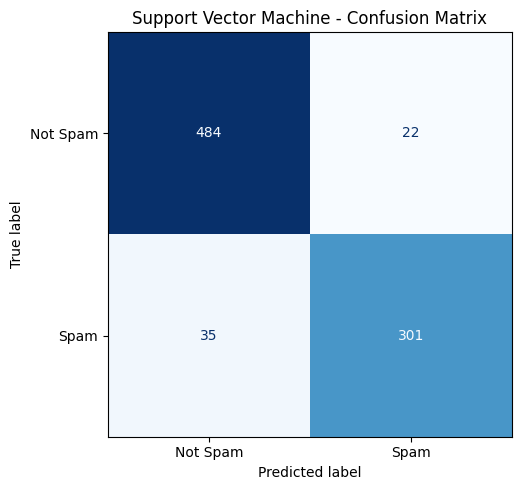

Confusion Matrix:
[[484  22]
 [ 35 301]]

Classification Breakdown:
True Negatives (TN): 484
False Positives (FP): 22
False Negatives (FN): 35
True Positives (TP): 301
Correct Predictions: 785
Incorrect Predictions: 57


In [62]:

# ============================================================
# MODEL 5: SVM CONFUSION MATRIX
# ============================================================

# Calculate confusion matrix
svm_cm = confusion_matrix(y_test, svm_predictions)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=svm_cm,
    display_labels=["Not Spam", "Spam"]
)

disp.plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("Support Vector Machine - Confusion Matrix")
plt.tight_layout()
plt.show()

# Extract confusion matrix values
tn, fp, fn, tp = svm_cm.ravel()

print("Confusion Matrix:")
print(svm_cm)

print("\nClassification Breakdown:")
print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)
print("Correct Predictions:", tn + tp)
print("Incorrect Predictions:", fp + fn)



### 6.5.1 Support Vector Machine - Results and Interpretation

#### Evaluation Results

| Metric | Score |
|---|---:|
| Accuracy | 0.9323 |
| AUC | 0.9772 |
| Precision | 0.9319 |
| Recall | 0.8958 |
| F1-Score | 0.9135 |
| MCC | 0.8584 |

#### Confusion Matrix Analysis

| Actual / Predicted | Not Spam | Spam |
|---|---:|---:|
| Not Spam | 484 | 22 |
| Spam | 35 | 301 |

#### Key Observations

1. **Accuracy (93.23%):** SVM correctly classified
   785 out of 842 test emails.

2. **AUC (0.9772):** SVM achieved the highest AUC
   among the five classifiers.

3. **Precision (93.19%):** SVM achieved the highest
   precision, indicating fewer incorrectly flagged
   legitimate emails relative to predicted spam.

4. **Recall (89.58%):** SVM detected 301 of 336
   actual spam emails.

5. **F1-Score (0.9135):** SVM demonstrated a strong
   balance between precision and recall.

6. **MCC (0.8584):** SVM achieved strong overall
   classification performance.

#### Error Analysis

The model produced:
- 22 false positives: Legitimate emails flagged as spam.
- 35 false negatives: Spam emails classified as legitimate.

Compared with Logistic Regression, SVM produced
one fewer false positive but three additional
false negatives.

#### Interpretation

The RBF kernel enabled SVM to model nonlinear
relationships between email features.

SVM achieved marginally higher AUC and precision
than Logistic Regression.

However, Logistic Regression achieved slightly
higher accuracy, recall, F1-score, and MCC.

The performance differences between these two
models were relatively small.

#### Conclusion

SVM demonstrated competitive classification
performance and achieved the highest AUC and
precision in this experiment.

Logistic Regression remains the leading model
based on F1-score and MCC.

The final model selection will consider all six
evaluation metrics and the practical consequences
of classification errors.



## 7. Comparative Performance Evaluation

### 7.1 Objective

To systematically compare the predictive performance
of all five classification algorithms and identify
the most suitable model for email spam detection.

### 7.2 Models Evaluated

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

All models were evaluated using the same 842
held-out test observations.

### 7.3 Evaluation Metrics

| Metric | Evaluation Purpose |
|---|---|
| Accuracy | Overall proportion of correct predictions |
| ROC AUC | Ability to distinguish classes across thresholds |
| Precision | Reliability of predicted spam classifications |
| Recall | Ability to identify actual spam emails |
| F1-Score | Harmonic mean of precision and recall |
| MCC | Balanced measure using all confusion matrix outcomes |

### 7.4 Model Selection Strategy

The comparison considers both statistical performance
and the practical consequences of classification errors.

**Primary considerations:**

- F1-score for balancing precision and recall.
- MCC for assessing overall classification quality.
- Precision for minimizing legitimate emails
  incorrectly classified as spam.
- Recall for minimizing undetected spam emails.
- ROC AUC for evaluating discrimination across
  different classification thresholds.

### 7.5 Experimental Fairness

All five models use:

- The same cleaned Spambase dataset.
- The same 80:20 stratified train-test split.
- The same random state where applicable.
- The same six evaluation metrics.
- Appropriate model-specific preprocessing.

Hyperparameters were selected as baseline
configurations without systematic optimization.

### 7.6 Limitations

The evaluation uses a single train-test split.

Performance differences may vary with alternative
data partitions or hyperparameter configurations.

The final recommendation therefore applies to
the evaluated configurations and dataset rather
than establishing universal algorithm superiority.


FINAL CLASSIFICATION MODEL COMPARISON


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9347,0.9768,0.9297,0.9048,0.9170,0.8634
Support Vector Machine,0.9323,0.9772,0.9319,0.8958,0.9135,0.8584
KNN,0.9050,0.9570,0.9103,0.8452,0.8765,0.8009
Decision Tree,0.8848,0.9259,0.8567,0.8542,0.8554,0.7597
Naive Bayes,0.8361,0.9525,0.7240,0.9524,0.8226,0.6975


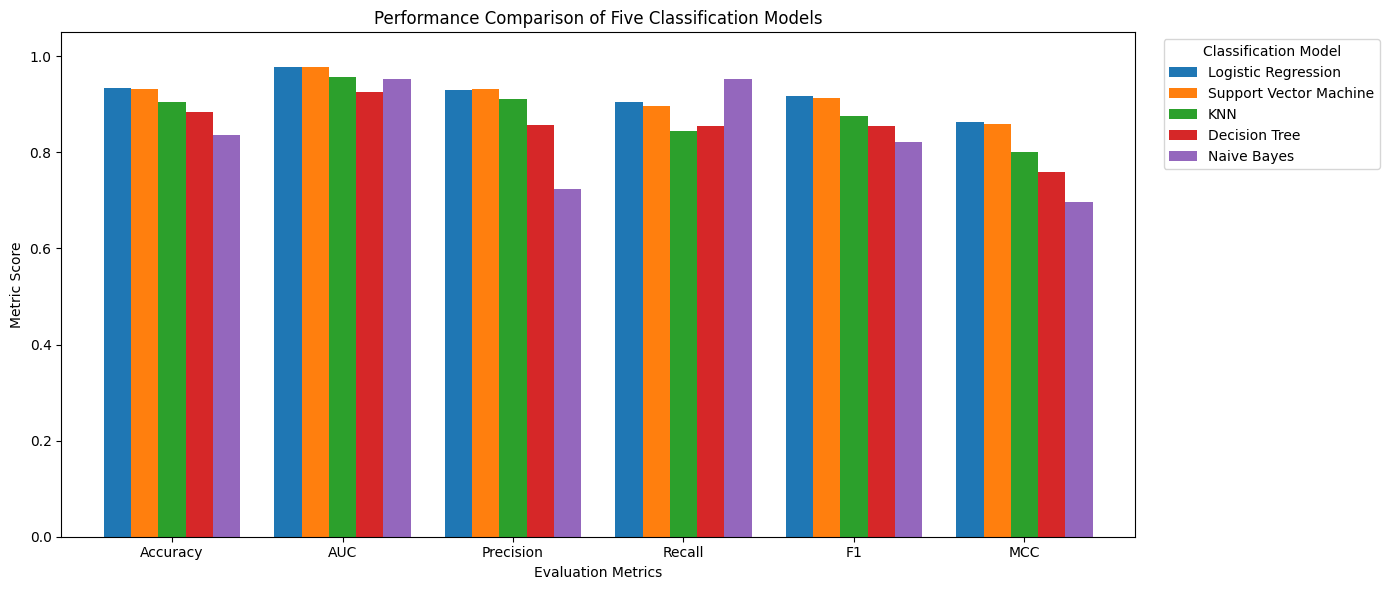


BEST MODEL BY EVALUATION METRIC
Accuracy: Logistic Regression (0.9347)
AUC: Support Vector Machine (0.9772)
Precision: Support Vector Machine (0.9319)
Recall: Naive Bayes (0.9524)
F1: Logistic Regression (0.9170)
MCC: Logistic Regression (0.8634)

OVERALL MODEL RANKING (F1 and MCC)


,F1,MCC
Logistic Regression,0.9170,0.8634
Support Vector Machine,0.9135,0.8584
KNN,0.8765,0.8009
Decision Tree,0.8554,0.7597
Naive Bayes,0.8226,0.6975


In [66]:

# ============================================================
# STEP 7: FINAL MODEL COMPARISON
# ============================================================

# Verify that all five models have been evaluated
expected_models = [
    "Logistic Regression",
    "Decision Tree",
    "KNN",
    "Naive Bayes",
    "Support Vector Machine"
]

missing_models = [
    name for name in expected_models
    if name not in model_results
]

assert not missing_models, f"Missing models: {missing_models}"

# 1. Create final comparison table
comparison_df = pd.DataFrame.from_dict(
    model_results,
    orient="index"
)

# Rank models by F1-score and MCC
comparison_df = comparison_df.sort_values(
    by=["F1", "MCC"],
    ascending=False
)

print("FINAL CLASSIFICATION MODEL COMPARISON")
display(comparison_df.round(4))

# 2. Visualize all six evaluation metrics
ax = comparison_df.T.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Performance Comparison of Five Classification Models")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Metric Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(
    title="Classification Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# 3. Identify the leading model for each metric
print("\nBEST MODEL BY EVALUATION METRIC")

for metric in comparison_df.columns:
    best_model = comparison_df[metric].idxmax()
    best_score = comparison_df.loc[best_model, metric]

    print(f"{metric}: {best_model} ({best_score:.4f})")

# 4. Overall ranking
print("\nOVERALL MODEL RANKING (F1 and MCC)")
display(comparison_df[["F1", "MCC"]].round(4))



## 8. Final Model Selection and Interpretation

### 8.1 Objective

To identify the most suitable classification model
for email spam detection based on the experimental
results and practical classification requirements.

### 8.2 Comparative Performance Summary

| Model | Accuracy | F1 | MCC |
|---|---:|---:|---:|
| Logistic Regression | 0.9347 | 0.9170 | 0.8634 |
| Decision Tree | 0.8848 | 0.8554 | 0.7597 |
| KNN | 0.9050 | 0.8765 | 0.8009 |
| Gaussian Naive Bayes | 0.8361 | 0.8226 | 0.6975 |
| SVM | 0.9323 | 0.9135 | 0.8584 |

### 8.3 Best Model: Logistic Regression

Logistic Regression is selected as the best overall
classifier for this experiment.

**Justification:**

1. **Highest Accuracy (93.47%)**
   Correctly classified 787 of 842 test emails.

2. **Highest F1-Score (0.9170)**
   Achieved the strongest balance between
   precision and recall.

3. **Highest MCC (0.8634)**
   Demonstrated the strongest overall classification
   performance among the evaluated configurations.

4. **Low Classification Error**
   Produced 23 false positives and 32 false negatives.

5. **Model Simplicity**
   Provides a relatively simple and interpretable
   baseline compared with nonlinear SVM.

### 8.4 Important Trade-offs

**Support Vector Machine**

SVM achieved the highest AUC (0.9772) and precision
(0.9319). Its performance was very close to Logistic
Regression, making it a strong alternative.

**Gaussian Naive Bayes**

Naive Bayes achieved the highest recall (0.9524),
detecting 320 of 336 spam emails.

However, it also produced 122 false positives,
making it less suitable when legitimate emails
must be protected from incorrect filtering.

**K-Nearest Neighbors**

KNN achieved reasonable performance but missed
more spam emails than Logistic Regression.

**Decision Tree**

The Decision Tree provided an interpretable
rule-based approach but achieved lower predictive
performance in the evaluated configuration.

### 8.5 Limitations

The models were evaluated using a single
stratified train-test split.

Hyperparameters were selected without systematic
cross-validation or optimization.

Therefore, the results demonstrate comparative
performance under the selected experimental
conditions rather than universal model superiority.

### 8.6 Final Conclusion

Logistic Regression is recommended as the preferred
classifier for this experiment based on its accuracy,
F1-score, MCC, and balanced classification errors.

SVM remains a competitive alternative, particularly
when maximizing AUC or precision is prioritized.

The selected model will be included in the
Streamlit application for interactive prediction.


In [71]:

# ============================================================
# STEP 9: MODEL SERIALIZATION FOR STREAMLIT
# ============================================================

# Create directory for saved models
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

# Map model names to trained objects
trained_models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "KNN": knn_model,
    "Naive Bayes": nb_model,
    "Support Vector Machine": svm_model
}

# Define output filenames
model_filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

# Save all trained models
for name, model in trained_models.items():
    filepath = model_dir / model_filenames[name]
    joblib.dump(model, filepath)
    print(f"Saved: {filepath}")

# Save feature names for consistent inference
joblib.dump(list(X_train.columns), model_dir / "feature_names.joblib")

# Verify saved files
print("\nSaved Model Files:")
for filepath in sorted(model_dir.glob("*.joblib")):
    print(f"{filepath.name}: {filepath.stat().st_size / 1024:.2f} KB")

print("\nAll models saved successfully!")


Saved: models/logistic_regression.joblib
Saved: models/decision_tree.joblib
Saved: models/knn.joblib
Saved: models/naive_bayes.joblib
Saved: models/svm.joblib

Saved Model Files:
decision_tree.joblib: 7.27 KB
feature_names.joblib: 0.74 KB
knn.joblib: 1529.94 KB
logistic_regression.joblib: 4.31 KB
naive_bayes.joblib: 3.77 KB
svm.joblib: 488.09 KB

All models saved successfully!


In [73]:

# ============================================================
# STEP 10: EXPORT DATA AND EVALUATION RESULTS
# ============================================================

# Create output directory
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Export test dataset with actual labels
test_data = X_test.copy()
test_data["spam"] = y_test

test_data.to_csv(
    output_dir / "test_data_with_labels.csv",
    index=False
)

# 2. Export features only for Streamlit predictions
X_test.to_csv(
    output_dir / "test_data_for_prediction.csv",
    index=False
)

# 3. Export final model comparison
comparison_df.to_csv(
    output_dir / "model_comparison.csv",
    index_label="Model"
)

# 4. Validate exported files
print("Exported Files:\n")

for filepath in sorted(output_dir.glob("*.csv")):
    exported_df = pd.read_csv(filepath)
    print(f"{filepath.name}: {exported_df.shape}")

# 5. Verify prediction dataset
assert pd.read_csv(
    output_dir / "test_data_for_prediction.csv"
).shape == (842, 57)

print("\nAll CSV files exported successfully!")


Exported Files:

model_comparison.csv: (5, 7)
test_data_for_prediction.csv: (842, 57)
test_data_with_labels.csv: (842, 58)

All CSV files exported successfully!


In [75]:

# ============================================================
# STEP 11: MODEL RELOADING AND VALIDATION
# ============================================================

validation_results = []

for name, original_model in trained_models.items():

    # Load saved model
    model_path = model_dir / model_filenames[name]
    loaded_model = joblib.load(model_path)

    # Generate predictions
    original_predictions = original_model.predict(X_test)
    loaded_predictions = loaded_model.predict(X_test)

    # Compare predictions
    predictions_match = np.array_equal(
        original_predictions,
        loaded_predictions
    )

    validation_results.append({
        "Model": name,
        "Predictions Match": predictions_match,
        "Test Records": len(loaded_predictions),
        "Status": "PASS" if predictions_match else "FAIL"
    })

# Display validation results
validation_df = pd.DataFrame(validation_results)

print("Saved Model Validation Results:")
display(validation_df)

# Verify feature names
saved_features = joblib.load(
    model_dir / "feature_names.joblib"
)

assert saved_features == list(X_test.columns)
assert validation_df["Predictions Match"].all()

print("\nAll five models validated successfully!")
print("Feature schema verified.")
print("Models are ready for Streamlit integration.")


Saved Model Validation Results:


,Model,Predictions Match,Test Records,Status
0,Logistic Regression,True,842,PASS
1,Decision Tree,True,842,PASS
2,KNN,True,842,PASS
3,Naive Bayes,True,842,PASS
4,Support Vector Machine,True,842,PASS



All five models validated successfully!
Feature schema verified.
Models are ready for Streamlit integration.



## 9. Final Experiment Summary and Conclusion

### 9.1 Experiment Overview

This experiment implemented and compared five
supervised classification algorithms for email
spam detection using the UCI Spambase dataset.

**Student ID:** 2026AK05228

### 9.2 Data Preparation

- Original observations: 4,601
- Duplicate records removed: 391
- Cleaned observations: 4,210
- Input features: 57
- Training observations: 3,368
- Testing observations: 842
- Train-test split: 80:20 (stratified)

Feature scaling was applied through pipelines
for Logistic Regression, KNN, and SVM.

### 9.3 Experimental Findings

All five classifiers were evaluated using Accuracy,
ROC AUC, Precision, Recall, F1-score, and MCC.

Based on the observed results:

- Logistic Regression achieved the highest Accuracy,
  F1-score, and MCC.
- SVM achieved the highest AUC and Precision.
- Gaussian Naive Bayes achieved the highest Recall.
- KNN performed better than Decision Tree in
  overall F1-score and MCC.

### 9.4 Recommended Model

Logistic Regression is selected as the preferred
classifier for this experiment.

It achieved:

- Accuracy: 93.47%
- AUC: 0.9768
- Precision: 92.97%
- Recall: 90.48%
- F1-score: 0.9170
- MCC: 0.8634

The model correctly classified 787 of 842
test observations.

### 9.5 Limitations

The evaluation was conducted using a single
train-test split without systematic hyperparameter
optimization.

The Spambase dataset may not fully represent
modern email spam patterns.

Therefore, the results should be interpreted
within the scope of this dataset and experiment.

### 9.6 Deployment Readiness

All five trained classifiers were serialized
using Joblib.

The saved models were reloaded and their
predictions verified against the original models.

The test dataset and model comparison results
were exported as CSV files.

### 9.7 Conclusion

The experiment demonstrates that classifier
performance depends on the learning algorithm,
its assumptions, and the evaluation metric.

Logistic Regression provided the strongest overall
performance for the selected experimental setup.

The next phase involves developing an interactive
Streamlit application that loads the saved models,
accepts test data, and displays classification
predictions without retraining.


In [78]:

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PAGE CONFIGURATION
# ------------------------------------------------------------
st.set_page_config(
    page_title="Email Spam Classification",
    page_icon="📧",
    layout="wide"
)

st.title("Email Spam Classification")
st.caption(
    "BITS Pilani | Machine Learning Assignment 2 | "
    "Student ID: 2026AK05228"
)

st.markdown(
    "Compare five trained machine learning classifiers "
    "and predict whether uploaded emails are spam."
)

# ------------------------------------------------------------
# LOAD SAVED MODELS
# ------------------------------------------------------------
MODEL_DIR = Path("models")

MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

@st.cache_resource
def load_models():
    models = {}
    for name, filename in MODEL_FILES.items():
        models[name] = joblib.load(MODEL_DIR / filename)

    features = joblib.load(
        MODEL_DIR / "feature_names.joblib"
    )
    return models, features

try:
    models, feature_names = load_models()
except Exception as error:
    st.error(f"Unable to load saved models: {error}")
    st.stop()

# ------------------------------------------------------------
# SIDEBAR
# ------------------------------------------------------------
st.sidebar.header("Model Configuration")

selected_model = st.sidebar.selectbox(
    "Select Classification Model",
    list(models.keys())
)

st.sidebar.success("All five trained models loaded")

# ------------------------------------------------------------
# MODEL COMPARISON
# ------------------------------------------------------------
st.header("1. Model Performance Comparison")

comparison_path = Path("outputs/model_comparison.csv")

if comparison_path.exists():
    comparison = pd.read_csv(comparison_path)
    st.dataframe(comparison, use_container_width=True)
else:
    st.info("Model comparison file is not available.")

# ------------------------------------------------------------
# CSV UPLOAD
# ------------------------------------------------------------
st.header("2. Upload Test Dataset")

uploaded_file = st.file_uploader(
    "Upload a CSV containing the 57 input features",
    type=["csv"]
)

if uploaded_file is not None:

    data = pd.read_csv(uploaded_file)

    st.subheader("Uploaded Data Preview")
    st.dataframe(data.head(10), use_container_width=True)

    # Validate required features
    missing_features = [
        col for col in feature_names
        if col not in data.columns
    ]

    if missing_features:
        st.error(
            f"Missing required features: {missing_features}"
        )
        st.stop()

    X_input = data[feature_names].copy()

    # Validate numeric input
    try:
        X_input = X_input.apply(pd.to_numeric, errors="raise")
    except (ValueError, TypeError):
        st.error("All 57 input features must be numeric.")
        st.stop()

    if X_input.isnull().any().any():
        st.error("Input features contain missing values.")
        st.stop()

    # --------------------------------------------------------
    # GENERATE PREDICTIONS
    # --------------------------------------------------------
    st.header("3. Classification Results")

    model = models[selected_model]

    predictions = model.predict(X_input)
    probabilities = model.predict_proba(X_input)[:, 1]

    results = data.copy()
    results["Predicted_Class"] = predictions
    results["Prediction_Label"] = np.where(
        predictions == 1, "Spam", "Not Spam"
    )
    results["Spam_Probability"] = probabilities

    col1, col2, col3 = st.columns(3)

    col1.metric("Total Emails", len(results))
    col2.metric("Predicted Spam", int(sum(predictions)))
    col3.metric(
        "Predicted Not Spam",
        int(sum(predictions == 0))
    )

    st.dataframe(results, use_container_width=True)

    st.download_button(
        "Download Predictions",
        results.to_csv(index=False).encode("utf-8"),
        file_name="spam_predictions.csv",
        mime="text/csv"
    )

    # --------------------------------------------------------
    # EVALUATE IF ACTUAL LABELS ARE PROVIDED
    # --------------------------------------------------------
    if "spam" in data.columns:

        st.header("4. Evaluation Against Actual Labels")

        y_actual = data["spam"]

        if not y_actual.isin([0, 1]).all():
            st.error("The spam column must contain only 0 and 1.")
            st.stop()

        if y_actual.nunique() < 2:
            st.warning(
                "Both classes are required to calculate ROC AUC."
            )
            auc = np.nan
        else:
            auc = roc_auc_score(y_actual, probabilities)

        metrics = {
            "Accuracy": accuracy_score(y_actual, predictions),
            "AUC": auc,
            "Precision": precision_score(
                y_actual, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_actual, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_actual, predictions, zero_division=0
            ),
            "MCC": matthews_corrcoef(
                y_actual, predictions
            )
        }

        st.dataframe(
            pd.DataFrame([metrics]).round(4),
            use_container_width=True
        )

        cm = confusion_matrix(
            y_actual, predictions, labels=[0, 1]
        )

        fig, ax = plt.subplots(figsize=(6, 4))

        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Not Spam", "Spam"]
        ).plot(ax=ax, cmap="Blues", colorbar=False)

        st.pyplot(fig)
        plt.close(fig)

st.divider()
st.caption(
    "BITS Pilani | ML Assignment 2 | "
    "Student ID: 2026AK05228"
)


Writing app.py


In [82]:

# ============================================================
# STEP 12: STREAMLIT DEPLOYMENT PREPARATION
# ============================================================

# 1. Create requirements.txt
requirements = [
    "streamlit",
    "pandas",
    "numpy",
    "scikit-learn",
    "matplotlib",
    "joblib"
]

Path("requirements.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("requirements.txt created successfully!")

# 2. Validate required application files
required_files = [
    Path("app.py"),
    Path("requirements.txt"),
    Path("models/feature_names.joblib"),
    Path("models/logistic_regression.joblib"),
    Path("models/decision_tree.joblib"),
    Path("models/knn.joblib"),
    Path("models/naive_bayes.joblib"),
    Path("models/svm.joblib"),
    Path("outputs/model_comparison.csv"),
    Path("outputs/test_data_for_prediction.csv"),
    Path("outputs/test_data_with_labels.csv")
]

validation = pd.DataFrame([
    {
        "File": str(file),
        "Exists": file.is_file(),
        "Size (KB)": round(file.stat().st_size / 1024, 2)
        if file.is_file() else 0
    }
    for file in required_files
])

display(validation)

# 3. Verify deployment readiness
assert validation["Exists"].all(), (
    "Some required files are missing."
)

print("\nAll deployment files verified successfully!")


requirements.txt created successfully!


,File,Exists,Size (KB)
0,app.py,True,6.13
1,requirements.txt,True,0.05
2,models/feature_names.joblib,True,0.74
3,models/logistic_regression.joblib,True,4.31
4,models/decision_tree.joblib,True,7.27
5,models/knn.joblib,True,1529.94
6,models/naive_bayes.joblib,True,3.77
7,models/svm.joblib,True,488.09
8,outputs/model_comparison.csv,True,0.66
9,outputs/test_data_for_prediction.csv,True,197.36



All deployment files verified successfully!


In [84]:

# ============================================================
# STEP 13: PACKAGE ASSIGNMENT FOR DEPLOYMENT
# ============================================================

import zipfile

zip_name = "BITS_ML_Assignment_2_2026AK05228.zip"

files_to_package = [
    Path("app.py"),
    Path("requirements.txt"),
    *Path("models").glob("*.joblib"),
    *Path("outputs").glob("*.csv")
]

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as archive:
    for file in files_to_package:
        if file.is_file():
            archive.write(file, arcname=str(file))

print("ZIP created:", zip_name)
print("Files included:", len(files_to_package))
print("Size (MB):", round(Path(zip_name).stat().st_size / 1048576, 2))


ZIP created: BITS_ML_Assignment_2_2026AK05228.zip
Files included: 11
Size (MB): 0.52
